In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import torch

## Training data

`Facial` maps **N frames onto one image**, so a training item is a whole identity: several
anonymized observations of a person, and the single clear image the decoder should produce from
them. `meles.training.facial.FacialFrames` assembles those items — it is to `Facial` what
`AnonymizedPairs` is to pix2pix.

- The **inputs** are frames from `ytfaces.parquet`, anonymized at their native resolution and
  *then* aligned to 112x112. That order matters: the pipeline anonymizes a frame at whatever size
  it is, so blurring a 112x112 crop would fit a radius the model never meets again at inference.
- The **target** is the frame picked in `07_target_selection.ipynb` — the one a recogniser
  identifies best among each identity's most frontal. Pose consistency matters because
  `FacialAggregator` pools with a *fixed* learned query, so nothing tells the decoder which pose
  to emit; scattered target poses leave it only their average to learn.
- The face is located on the **clear** frame, and that area is used to both anonymize and align.
  A black bar is precisely what a detector cannot find, so detecting on the anonymized frame
  would hand the model letterboxed whole frames for the anonymization that matters most.
- Input frames come from the identity's **other videos**, so the decoder cannot reconstruct the
  target off its own shot's background and lighting instead of off the face.

The split holds out **identities, not frames**. This trains on the same dataset the experiment
scores, so splitting by frame would put the same face on both sides and the validation loss would
only measure memorisation. Holding identities out is what keeps the decoder's prior from
containing the gallery — the trap `meles.training.pairs` avoids by training pix2pix on CelebA.

### One model, four anonymizations

Rather than one model per method, a single model covers all of them, introduced as a **curriculum**:

| curriculum stage | methods drawn from |
| --- | --- |
| 0 | `none` |
| 1 | `none`, `gaussianblur` |
| 2 | `none`, `gaussianblur`, `pixelation` |
| 3 | `none`, `gaussianblur`, `pixelation`, `blackbar` |

Each stage keeps everything before it and adds one method, so the dataset gets strictly harder.
`blackbar` comes last because it *removes* the face rather than obscuring it — there is no inverse
to learn, only a prior over what the other frames imply, so it is the method that depends most on
the earlier stages already working.

Two details that are easy to get wrong:

- **A whole item shares one anonymization**, drawn per identity rather than per frame. A sweep leg
  pins one `frame_anonymizer` and anonymizes every frame the same way, so an item mixing methods
  is a distribution the model would never meet at inference.
- **`method` indexes the full curriculum**, not the active prefix, so index 3 means `blackbar` at
  every stage. That is what makes a per-method validation loss comparable across stages — which is
  the number that tells you whether adding `blackbar` cost you `gaussianblur`.

The model side is `Facial(methods=len(CURRICULUM))`: a learned embedding per method, added to the
aggregator's pooling query. The query is otherwise one constant shared by every input, and undoing
a blur is not the same operation as inventing a face behind a black bar. It is zero-initialised, so
it starts out as a no-op and only earns its influence. Passing the method is fair game — a sweep leg
names its anonymization, and blur, blocks and a bar are not hard to tell apart.

*(The "Stage 1 / Stage 2" cells further down are a different axis: they freeze and then fine-tune
the encoder. Both schedules run over the curriculum.)*

In [2]:
from torch.utils.data import DataLoader

from meles.training import CURRICULUM, FacialFrames, split_identities

DATASET_PATH = Path("../../data")

FRAMES = 8  # N, how many anonymized observations make up one item
BATCH = 10
WORKERS = 4

# The widened structure 07_target_selection built (MIN_VIDEOS_PER_IDENTITY = 2). Not
# "ytfaces.parquet" -- that is the Snakemake sweep's dataset and still holds only the
# identities with three or more videos. Not "ytfaces_values.parquet" either: same frames,
# but it carries the 512-float embedding per row, which costs ~2.9 GB of RAM here and is
# never read -- this dataset only needs identity, video and path.
structure_df = pd.read_parquet(DATASET_PATH / "ytfaces_wide.parquet")
targets_df = pd.read_parquet(DATASET_PATH / "ytfaces_targets.parquet")

# Held out by identity, never by frame.
train_identities, validation_identities = split_identities(targets_df["identity"], validation=0.1, seed=0)

train_frames = FacialFrames(
    structure_df, targets_df, DATASET_PATH,
    curriculum=CURRICULUM, identities=train_identities, frames=FRAMES,
)

# Validation differs from training in three ways, and each one is load-bearing:
#   stage=last    so every method is measured from epoch 1 -- otherwise a method has no baseline
#                 to be compared against on the epoch it unlocks;
#   deterministic so the frames and the flip are fixed and the loss means the same thing in
#                 epoch 1 and epoch 100;
#   all_methods   so every identity is evaluated under *every* anonymization rather than one
#                 drawn at random. Drawing would leave the per-method counts to chance -- a
#                 method that drew no items would have no loss at all -- and this also pairs the
#                 comparison, since each method then sees the same identity on the same frames.
validation_frames = FacialFrames(
    structure_df, targets_df, DATASET_PATH,
    curriculum=CURRICULUM, identities=validation_identities, frames=FRAMES,
    stage=len(CURRICULUM) - 1, deterministic=True, all_methods=True,
)
validation_loader = DataLoader(
    validation_frames, batch_size=BATCH, shuffle=False, num_workers=WORKERS,
    pin_memory=True, persistent_workers=True,
)


def train_loader_for(stage):
    """
    A fresh loader for one curriculum stage.

    Rebuilt rather than mutated: a DataLoader forks its workers a *copy* of the dataset when its
    iterator is first made, and with 'persistent_workers' they outlive the epoch -- so calling
    'set_stage' on this process after that point would widen the parent and nothing else, and
    training would quietly stay on the old stage.
    """
    train_frames.set_stage(stage)
    return DataLoader(
        train_frames, batch_size=BATCH, shuffle=True, num_workers=WORKERS,
        pin_memory=True, persistent_workers=True, drop_last=True,
    )


train_loader = train_loader_for(0)

print(f"curriculum: {' -> '.join(CURRICULUM)}")
print(f"train:      {len(train_frames):>4} identities, {len(train_loader):>3} batches")
print(f"            stage {train_frames.stage} of {train_frames.stages - 1}: {', '.join(train_frames.active)}")
per_method = len(validation_frames) // len(CURRICULUM)
print(f"validation: {per_method:>4} identities x {len(CURRICULUM)} methods "
      f"= {len(validation_frames)} items, {len(validation_loader)} batches")

curriculum: none -> gaussianblur -> pixelation -> blackbar
train:       904 identities,  90 batches
            stage 0 of 3: none
validation:  100 identities x 4 methods = 400 items, 40 batches


inputs (10, 8, 3, 112, 112) -> target (10, 3, 112, 112), method (10,)
range  [-1.00, 1.00]   methods in batch: [0]


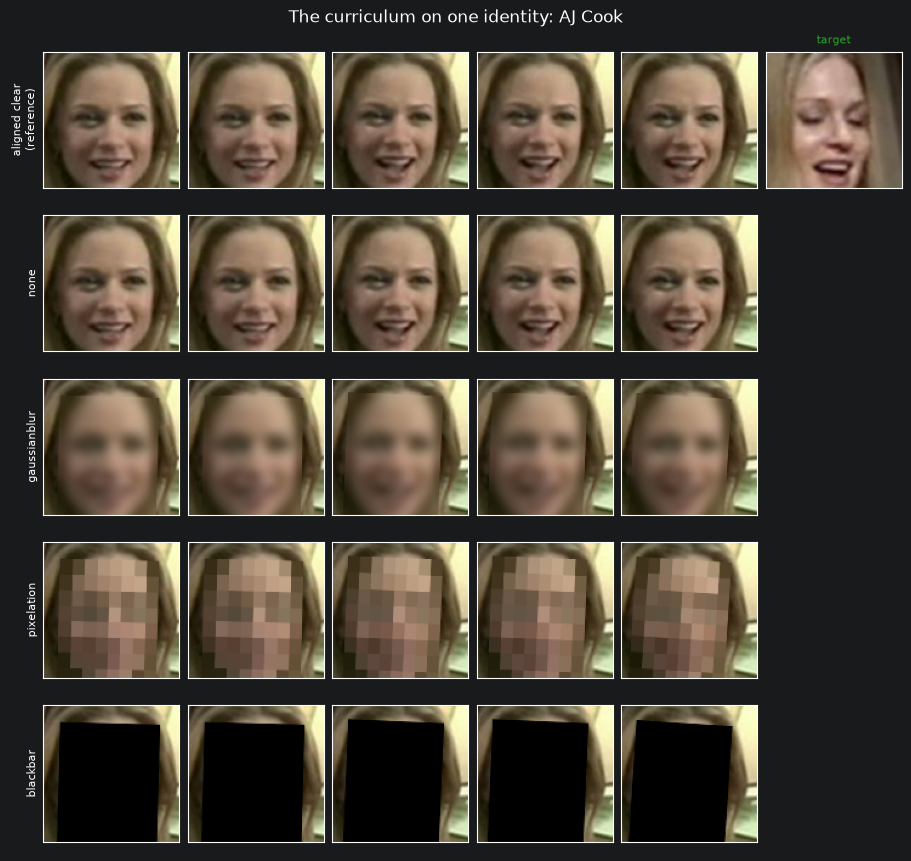

In [3]:
import cv2

# One batch, to confirm it is the shape Facial.forward takes. 'method' is the curriculum index
# every frame of that item was built with -- at stage 0 it is all zeros.
inputs, target, method = next(iter(train_loader))
print(f"inputs {tuple(inputs.shape)} -> target {tuple(target.shape)}, method {tuple(method.shape)}")
print(f"range  [{inputs.min():.2f}, {inputs.max():.2f}]   methods in batch: {sorted(set(method.tolist()))}")

# One identity under every method in the curriculum, one column per frame. The top row is the
# clear alignment: if those faces are centred the geometry is right, and each row below is then
# that anonymization doing its job. Heavy anonymization alone looks a lot like a misaligned crop,
# which is why the clear row is here to compare against.
SHOWN = 5
identity = train_frames.identities[0]
paths = train_frames.pool[identity][:SHOWN]
rows = [(None, "aligned clear\n(reference)")] + [(i, name) for i, name in enumerate(train_frames.names)]

fig, axes = plt.subplots(len(rows), SHOWN + 1, figsize=(1.5 * (SHOWN + 1), 1.7 * len(rows)), layout="constrained")
for row, (method_index, label) in enumerate(rows):
    for column, path in enumerate(paths):
        crop = train_frames.crop(path, method_index, flip=False)
        axes[row, column].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_ylabel(label, fontsize=8)
    axes[row, SHOWN].set_axis_off()

# The target, shown once against the clear row; the model only ever sees it as the thing to produce.
axes[0, SHOWN].set_axis_on()
axes[0, SHOWN].imshow(cv2.cvtColor(train_frames.crop(train_frames.target[identity], None, False), cv2.COLOR_BGR2RGB))
axes[0, SHOWN].set_title("target", fontsize=8, color="tab:green")

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(f"The curriculum on one identity: {identity.replace('_', ' ')}", fontsize=12)
plt.show()

In [4]:
from meles.frame_aggregation.facial import Facial
from meles.frame_aggregation.pix2pix import to_image
from meles.frame_embedder import FrameEmbedder, models
from meles.training import (
    ContrastiveIdentityLoss, FacialTrainer, IdentityLoss, WeightedCriterion,
    identification, l1_per_item,
)

EPOCHS = 100
EPOCHS_PER_CURRICULUM_STAGE = EPOCHS // len(CURRICULUM)

# Named per loss, so a rerun lands beside the previous run instead of overwriting it.
# Renamed again: the validation gallery grew with the dataset, so rank-1 from this run is
# not comparable to the earlier ones and should not share their file.
CHECKPOINT = "models/facial.wide.pt"

# 'methods' conditions the aggregator's pooling query on which anonymization the inputs carry.
model = Facial(weights="models/iresnet34.pth", methods=len(CURRICULUM)).cuda()

# --- the loss ------------------------------------------------------------------------------
# Three terms, each answering a different question:
#   l1           are these the right pixels?  Keeps the output a face at all. Kept, but given the
#                smallest share -- alone it produces the average face.
#   identity     is this the right person?    1 - cosine to the target under a frozen recogniser.
#   contrastive  this person *rather than*    InfoNCE over the batch. Cosine can rise towards
#                anyone else?                 everyone at once, which moves the distance and
#                                             leaves rank-1 where it was; only this ranks.
#
# Weights put the terms at comparable magnitudes given where the last run settled: l1 ~0.33,
# 1 - cos ~0.87, InfoNCE ~ln(BATCH) ~2.3 at chance. Identity now carries ~70% of the total where
# it carried 44%. A starting point, not tuned -- rank-1 below is what to tune them against.
critic = IdentityLoss(weights="models/iresnet34.pth")
criterion = WeightedCriterion({
    "l1": (1.0, l1_per_item),
    "identity": (1.0, critic),
    # Shares the critic's weights rather than loading a second copy of the same 137 MB network.
    "contrastive": (0.2, ContrastiveIdentityLoss(encoder=critic.encoder)),
})

# --- the metric ----------------------------------------------------------------------------
# ArcFace (w600k_r50) judges, never iresnet34: the critic grading its own work would only confirm
# that the loss went down. This is also the model the experiment itself scores with.
arcface = FrameEmbedder(models.ARCFACE)


def embed_arcface(images):
    """(B, 3, 112, 112) in [-1, 1] -> L2-normalised ArcFace embeddings."""
    # Straight through the session: the crops are already aligned, and re-detecting on a blurry
    # reconstruction would preprocess the probes differently from the gallery.
    crops = [to_image(image) for image in images]
    vectors = np.asarray(arcface.session.run(arcface._blob(crops)), dtype=np.float64)
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def rank_metrics(trainer):
    """Rank-1/rank-5 identification, recorded into the history as 'val:rank1' etc."""
    return identification(trainer.model, validation_frames, embed_arcface)


people = len(validation_frames) // len(CURRICULUM)
print(f"gallery: {people} held-out identities, chance rank-1 = {1 / people:.1%}")

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gallery: 100 held-out identities, chance rank-1 = 1.0%


In [5]:
# Phase 1: encoder frozen. The decoder and the aggregator are trained from scratch, so they get
# the full learning rate; the pretrained encoder is held still until they are no longer random.
trainer = FacialTrainer(model=model, methods=CURRICULUM, criterion=criterion, encoder_frozen=True)

history = trainer.fit(
    train_loader_for,
    validation_loader,
    epochs_per_stage=EPOCHS_PER_CURRICULUM_STAGE,
    checkpoint=CHECKPOINT,
    metrics=rank_metrics,
    # Rank-1 swings ~5 points between neighbouring epochs on a 53-identity gallery, so the last
    # epoch is an arbitrary draw from the trajectory. Keep the best one too, as CHECKPOINT.best.pt.
    best="val:rank1",
)

print(f"epoch {trainer.epoch}, stage {trainer.stage}")
for term in criterion.terms:
    print(f"  val {term:<12} {history[f'val:{term}'][-1]:.4f}")
print(f"\n  {'method':<14} {'rank-1':>8} {'rank-5':>8} {'1 - cos':>9}")
for name in CURRICULUM:
    print(f"  {name:<14} {history[f'val:rank1_{name}'][-1]:>7.1%} {history[f'val:rank5_{name}'][-1]:>8.1%} "
          f"{history[f'val:identity_{name}'][-1]:>9.4f}")
print(f"  {'overall':<14} {history['val:rank1'][-1]:>7.1%} {history['val:rank5'][-1]:>8.1%}")

stage 1 (none, gaussianblur) epoch 25/25: 100%|██████████| 90/90 [00:17<00:00,  5.13it/s]
stage 2 (none, gaussianblur, pixelation) epoch 1/25: 100%|██████████| 90/90 [00:26<00:00,  3.45it/s]
stage 2 (none, gaussianblur, pixelation) epoch 2/25: 100%|██████████| 90/90 [00:24<00:00,  3.71it/s]
stage 2 (none, gaussianblur, pixelation) epoch 3/25: 100%|██████████| 90/90 [00:23<00:00,  3.78it/s]
stage 2 (none, gaussianblur, pixelation) epoch 4/25: 100%|██████████| 90/90 [00:22<00:00,  3.91it/s]
stage 2 (none, gaussianblur, pixelation) epoch 5/25: 100%|██████████| 90/90 [00:22<00:00,  3.99it/s]
stage 2 (none, gaussianblur, pixelation) epoch 6/25: 100%|██████████| 90/90 [00:21<00:00,  4.13it/s]
stage 2 (none, gaussianblur, pixelation) epoch 7/25: 100%|██████████| 90/90 [00:21<00:00,  4.26it/s]
stage 2 (none, gaussianblur, pixelation) epoch 8/25: 100%|██████████| 90/90 [00:21<00:00,  4.21it/s]
stage 2 (none, gaussianblur, pixelation) epoch 9/25: 100%|██████████| 90/90 [00:20<00:00,  4.41it/s]
s

epoch 100, stage 3
  val l1           0.3223
  val identity     0.8954
  val contrastive  0.2573

  method           rank-1   rank-5   1 - cos
  none             35.0%    54.0%    0.8322
  gaussianblur     19.0%    47.0%    0.8669
  pixelation        7.0%    18.0%    0.9316
  blackbar          3.0%    13.0%    0.9510
  overall          16.0%    33.0%


In [6]:
# Phase 2: unfreeze the encoder and fine-tune it at a tenth of the rate. Only the final
# curriculum stage is re-run -- the data is already as hard as it gets, and what changes here is
# which parameters move, not what they see.
trainer.set_encoder_frozen(False)

history = trainer.fit(
    train_loader_for,
    validation_loader,
    epochs_per_stage=EPOCHS_PER_CURRICULUM_STAGE,
    stages=[len(CURRICULUM) - 1],
    checkpoint=CHECKPOINT,
    metrics=rank_metrics,
    # Rank-1 swings ~5 points between neighbouring epochs on a 53-identity gallery, so the last
    # epoch is an arbitrary draw from the trajectory. Keep the best one too, as CHECKPOINT.best.pt.
    best="val:rank1",
)

stage 3 (none, gaussianblur, pixelation, blackbar) epoch 1/25: 100%|██████████| 90/90 [00:25<00:00,  3.52it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 2/25: 100%|██████████| 90/90 [00:23<00:00,  3.76it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 3/25: 100%|██████████| 90/90 [00:23<00:00,  3.83it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 4/25: 100%|██████████| 90/90 [00:22<00:00,  3.92it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 5/25: 100%|██████████| 90/90 [00:22<00:00,  3.99it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 6/25: 100%|██████████| 90/90 [00:21<00:00,  4.21it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 7/25: 100%|██████████| 90/90 [00:21<00:00,  4.26it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 8/25: 100%|██████████| 90/90 [00:20<00:00,  4.29it/s]
stage 3 (none, gaussianblur, pixelation, blackbar) epoch 9/25: 100%|██████████| 90/90 [00:20<00:00,  4.44it/s]
s

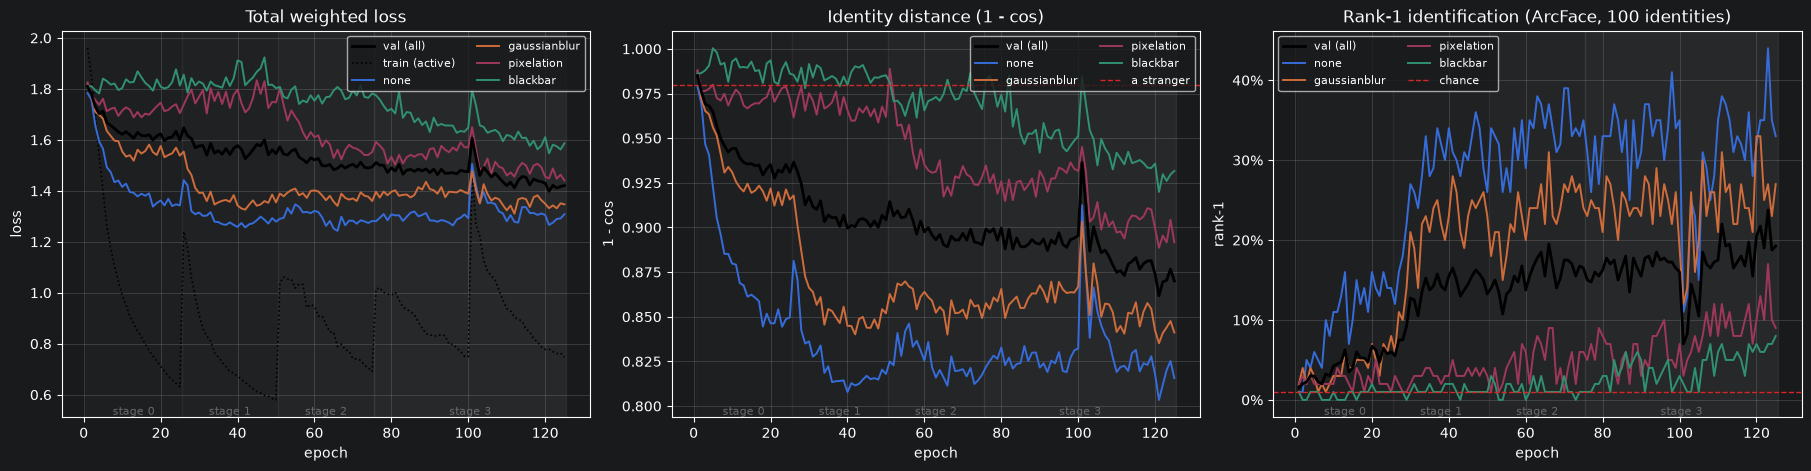

In [7]:
# Three views, because each hides what the next one shows.
#   left   total per method -- a rising total is equally consistent with progress on a newly
#          unlocked method and with quietly forgetting an old one; only the split separates them.
#   middle identity distance. Useful, but compressed: unrelated faces sit at ~1.0, so most of the
#          interesting range is squeezed into the last tenth.
#   right  rank-1, the number the experiment scores. This is the one to steer on.
epochs = range(1, len(history["val"]) + 1)
stages = history["stage"]


def stage_bands(ax):
    bottom, top = ax.get_ylim()
    for stage in sorted(set(stages)):
        first = stages.index(stage)
        last = len(stages) - 1 - stages[::-1].index(stage)
        ax.axvspan(first + 0.5, last + 1.5, color="tab:grey", alpha=0.05 + 0.03 * stage, zorder=0)
        ax.text(
            (first + last) / 2 + 1, bottom, f" stage {int(stage)} ",
            ha="center", va="bottom", fontsize=8, color="dimgrey",
        )
    ax.set_ylim(bottom, top)


has_rank = "val:rank1" in history
fig, axes = plt.subplots(1, 2 + has_rank, figsize=(6.0 * (2 + has_rank), 4.6), squeeze=False, layout="constrained")

ax = axes[0, 0]
ax.plot(epochs, history["val"], color="black", linewidth=2, label="val (all)", zorder=5)
ax.plot(epochs, history["train"], color="black", linestyle=":", linewidth=1.2, label="train (active)")
for name in CURRICULUM:
    ax.plot(epochs, history[f"val_{name}"], linewidth=1.4, label=name)
ax.set_title("Total weighted loss")
ax.set_ylabel("loss")

ax = axes[0, 1]
ax.plot(epochs, history["val:identity"], color="black", linewidth=2, label="val (all)", zorder=5)
for name in CURRICULUM:
    ax.plot(epochs, history[f"val:identity_{name}"], linewidth=1.4, label=name)
ax.axhline(0.98, color="tab:red", linestyle="--", linewidth=1, label="a stranger")
ax.set_title("Identity distance (1 - cos)")
ax.set_ylabel("1 - cos")

if has_rank:
    ax = axes[0, 2]
    ax.plot(epochs, history["val:rank1"], color="black", linewidth=2, label="val (all)", zorder=5)
    for name in CURRICULUM:
        ax.plot(epochs, history[f"val:rank1_{name}"], linewidth=1.4, label=name)
    ax.axhline(1 / people, color="tab:red", linestyle="--", linewidth=1, label="chance")
    ax.set_title(f"Rank-1 identification (ArcFace, {people} identities)")
    ax.set_ylabel("rank-1")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

for ax in axes.flat:
    ax.set_xlabel("epoch")
    ax.legend(ncols=2, fontsize=8, loc="best")
    ax.grid(alpha=0.3)
    stage_bands(ax)

plt.show()

## Storing the model, and looking at what it produces

`fit(checkpoint=...)` already wrote `CHECKPOINT` after **every** epoch, so the trained model is
on disk — paths are relative to this notebook, i.e. under `src/notebooks/models/`. The cell below
reloads it from scratch (no trainer needed) and reconstructs held-out faces.

- `trainer.save(path)` writes a resumable checkpoint: weights, optimiser state, epoch, stage and
  the full history.
- `trainer.save(path, inference_only=True)` drops the optimiser, which is roughly two thirds of
  the file — AdamW keeps two moment estimates per parameter. The result can be run but not resumed.
- `load_facial(path)` gives back `(model, metadata)` for inference without building a trainer.
- `trainer.load(path)` restores a run, including which encoder phase it was in.

epoch 125, stage 3, methods ['none', 'gaussianblur', 'pixelation', 'blackbar']


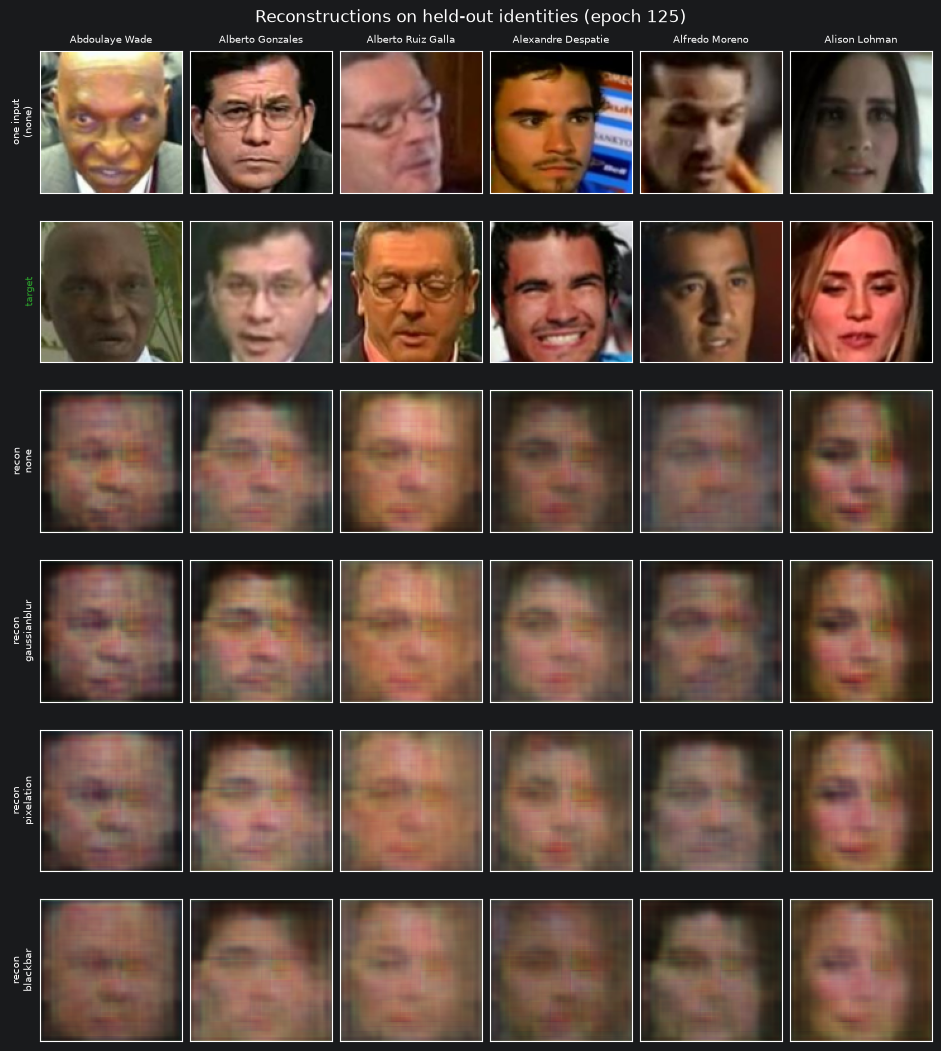

In [8]:
from meles.frame_aggregation.pix2pix import to_image
from meles.training.facial import load_facial, reconstruct

# A smaller export for inference: same weights, no optimiser state.
trainer.save(CHECKPOINT.replace(".pt", ".inference.pt"), inference_only=True)

# Reload from disk, so this cell works in a fresh kernel without retraining.
loaded, meta = load_facial(CHECKPOINT)
print(f"epoch {meta['epoch']}, stage {meta['stage']}, methods {meta['methods']}")

SHOWN = 6
width = len(CURRICULUM)

fig, axes = plt.subplots(width + 2, SHOWN, figsize=(1.55 * SHOWN, 1.75 * (width + 2)), layout="constrained")
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

for column in range(SHOWN):
    identity = validation_frames.identities[column]

    # 'all_methods' lays the validation set out as identity-major blocks, one entry per method,
    # so item 'column * width + i' is this identity under CURRICULUM[i] -- on the same frames.
    observations, target, _ = validation_frames[column * width]
    axes[0, column].imshow(cv2.cvtColor(to_image(observations[0]), cv2.COLOR_BGR2RGB))
    axes[0, column].set_title(identity.replace("_", " ")[:18], fontsize=7)
    axes[1, column].imshow(cv2.cvtColor(to_image(target), cv2.COLOR_BGR2RGB))

    for index in range(width):
        anonymized, _, method = validation_frames[column * width + index]
        produced = reconstruct(loaded, anonymized, int(method))[0]
        axes[2 + index, column].imshow(cv2.cvtColor(to_image(produced), cv2.COLOR_BGR2RGB))

axes[0, 0].set_ylabel(f"one input\n({CURRICULUM[0]})", fontsize=7)
axes[1, 0].set_ylabel("target", fontsize=7, color="tab:green")
for index, name in enumerate(CURRICULUM):
    axes[2 + index, 0].set_ylabel(f"recon\n{name}", fontsize=7)

fig.suptitle(f"Reconstructions on held-out identities (epoch {meta['epoch']})", fontsize=12)
plt.show()